In [1]:
dataset = [
    {
        "id": "emp_1",
        "name": "Alice Smith",
        "role": "AI Engineer",
        "team": "Search Team",
        "bio": "Alice builds semantic search systems using vector embeddings and LLMs.",
        "manager": "Bob Jones",
        "skills": ["Python", "PyTorch", "Pinecone"]
    },
    {
        "id": "emp_2",
        "name": "Bob Jones",
        "role": "Engineering Lead",
        "team": "Search Team",
        "bio": "Bob manages cloud architecture and coordinates server infrastructure.",
        "manager": None,
        "skills": ["AWS", "Kubernetes", "System Design"]
    }
]

In [2]:
import chromadb

# 1. Initialize an in-memory Vector DB
client = chromadb.Client()
collection = client.get_or_create_collection(name="employees")

# 2. Insert data into Vector DB
# Documents = text to embed; Metadatas = structured data to filter by
collection.add(
    ids=[item["id"] for item in dataset],
    documents=[item["bio"] for item in dataset],
    metadatas=[{"name": item["name"], "team": item["team"]} for item in dataset]
)

print(f"Total items in Vector DB: {collection.count()}")

# 3. Semantic Search
# Notice: The query words DO NOT appear in Alice's bio, but the MEANING matches.
query = "Who has experience with neural representations and generative models?"

results = collection.query(
    query_texts=[query],
    n_results=1
)

print("\n--- Vector DB Query Result ---")
print(f"Matched Person: {results['metadatas'][0][0]['name']}")
print(f"Matched Bio:    {results['documents'][0][0]}")
print(f"Distance Score: {results['distances'][0][0]:.4f} (lower is closer)")

C:\Users\SiddheshLihe\.cache\chroma\onnx_models\all-MiniLM-L6-v2\onnx.tar.gz: 100%|██████████| 79.3M/79.3M [01:36<00:00, 866kiB/s] 


Total items in Vector DB: 2

--- Vector DB Query Result ---
Matched Person: Alice Smith
Matched Bio:    Alice builds semantic search systems using vector embeddings and LLMs.
Distance Score: 1.5255 (lower is closer)


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Initialize a Directed Graph
G = nx.DiGraph()

# 2. Populate Nodes and Relationships
for emp in dataset:
    # Add Employee Node
    G.add_node(emp["name"], type="Employee", role=emp["role"])
    
    # Add Team Node & Edge
    G.add_node(emp["team"], type="Team")
    G.add_edge(emp["name"], emp["team"], relation="MEMBER_OF")
    
    # Add Skills & Edges
    for skill in emp["skills"]:
        G.add_node(skill, type="Skill")
        G.add_edge(emp["name"], skill, relation="HAS_SKILL")
        
    # Add Manager relationship
    if emp["manager"]:
        G.add_edge(emp["name"], emp["manager"], relation="REPORTS_TO")

# 3. Query the Graph (Multi-Hop Traversal)
# Question: "Who reports to Bob, and what are their skills?"
target_manager = "Bob Jones"

# Find who points to Bob with "REPORTS_TO"
direct_reports = [src for src, dst, data in G.in_edges(target_manager, data=True) if data["relation"] == "REPORTS_TO"]

print("--- Graph Traversal Result ---")
for report in direct_reports:
    # Find all skills connected to this report
    skills = [dst for _, dst, data in G.out_edges(report, data=True) if data["relation"] == "HAS_SKILL"]
    print(f"Direct Report: {report}")
    print(f"Skills of {report}: {skills}")

--- Graph Traversal Result ---
Direct Report: Alice Smith
Skills of Alice Smith: ['Python', 'PyTorch', 'Pinecone']


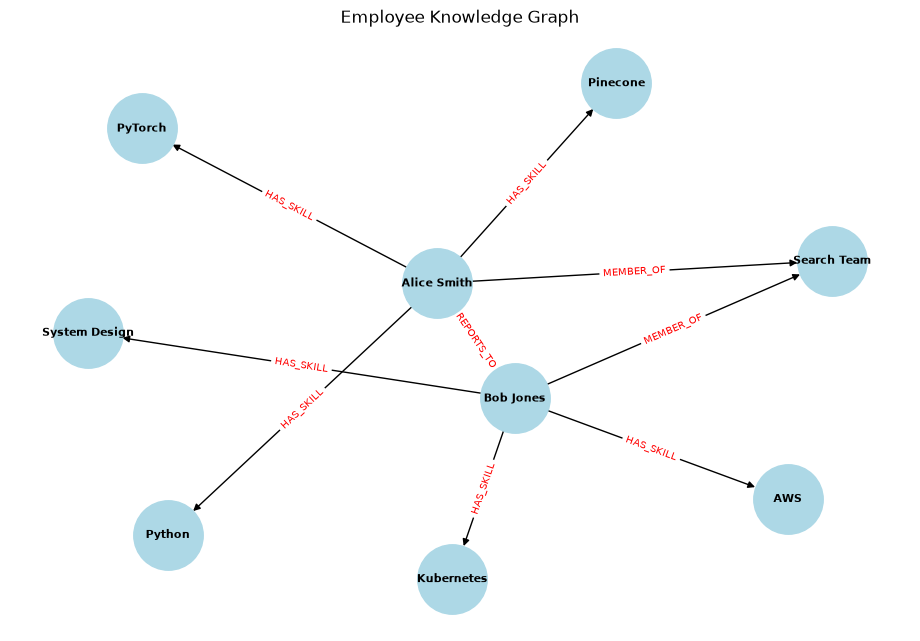

In [4]:
plt.figure(figsize=(9, 6))
pos = nx.spring_layout(G, seed=42)

nx.draw(G, pos, with_labels=True, node_color='lightblue', 
        node_size=2500, font_size=8, font_weight='bold', arrows=True)

edge_labels = nx.get_edge_attributes(G, 'relation')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red', font_size=7)

plt.title("Employee Knowledge Graph")
plt.show()